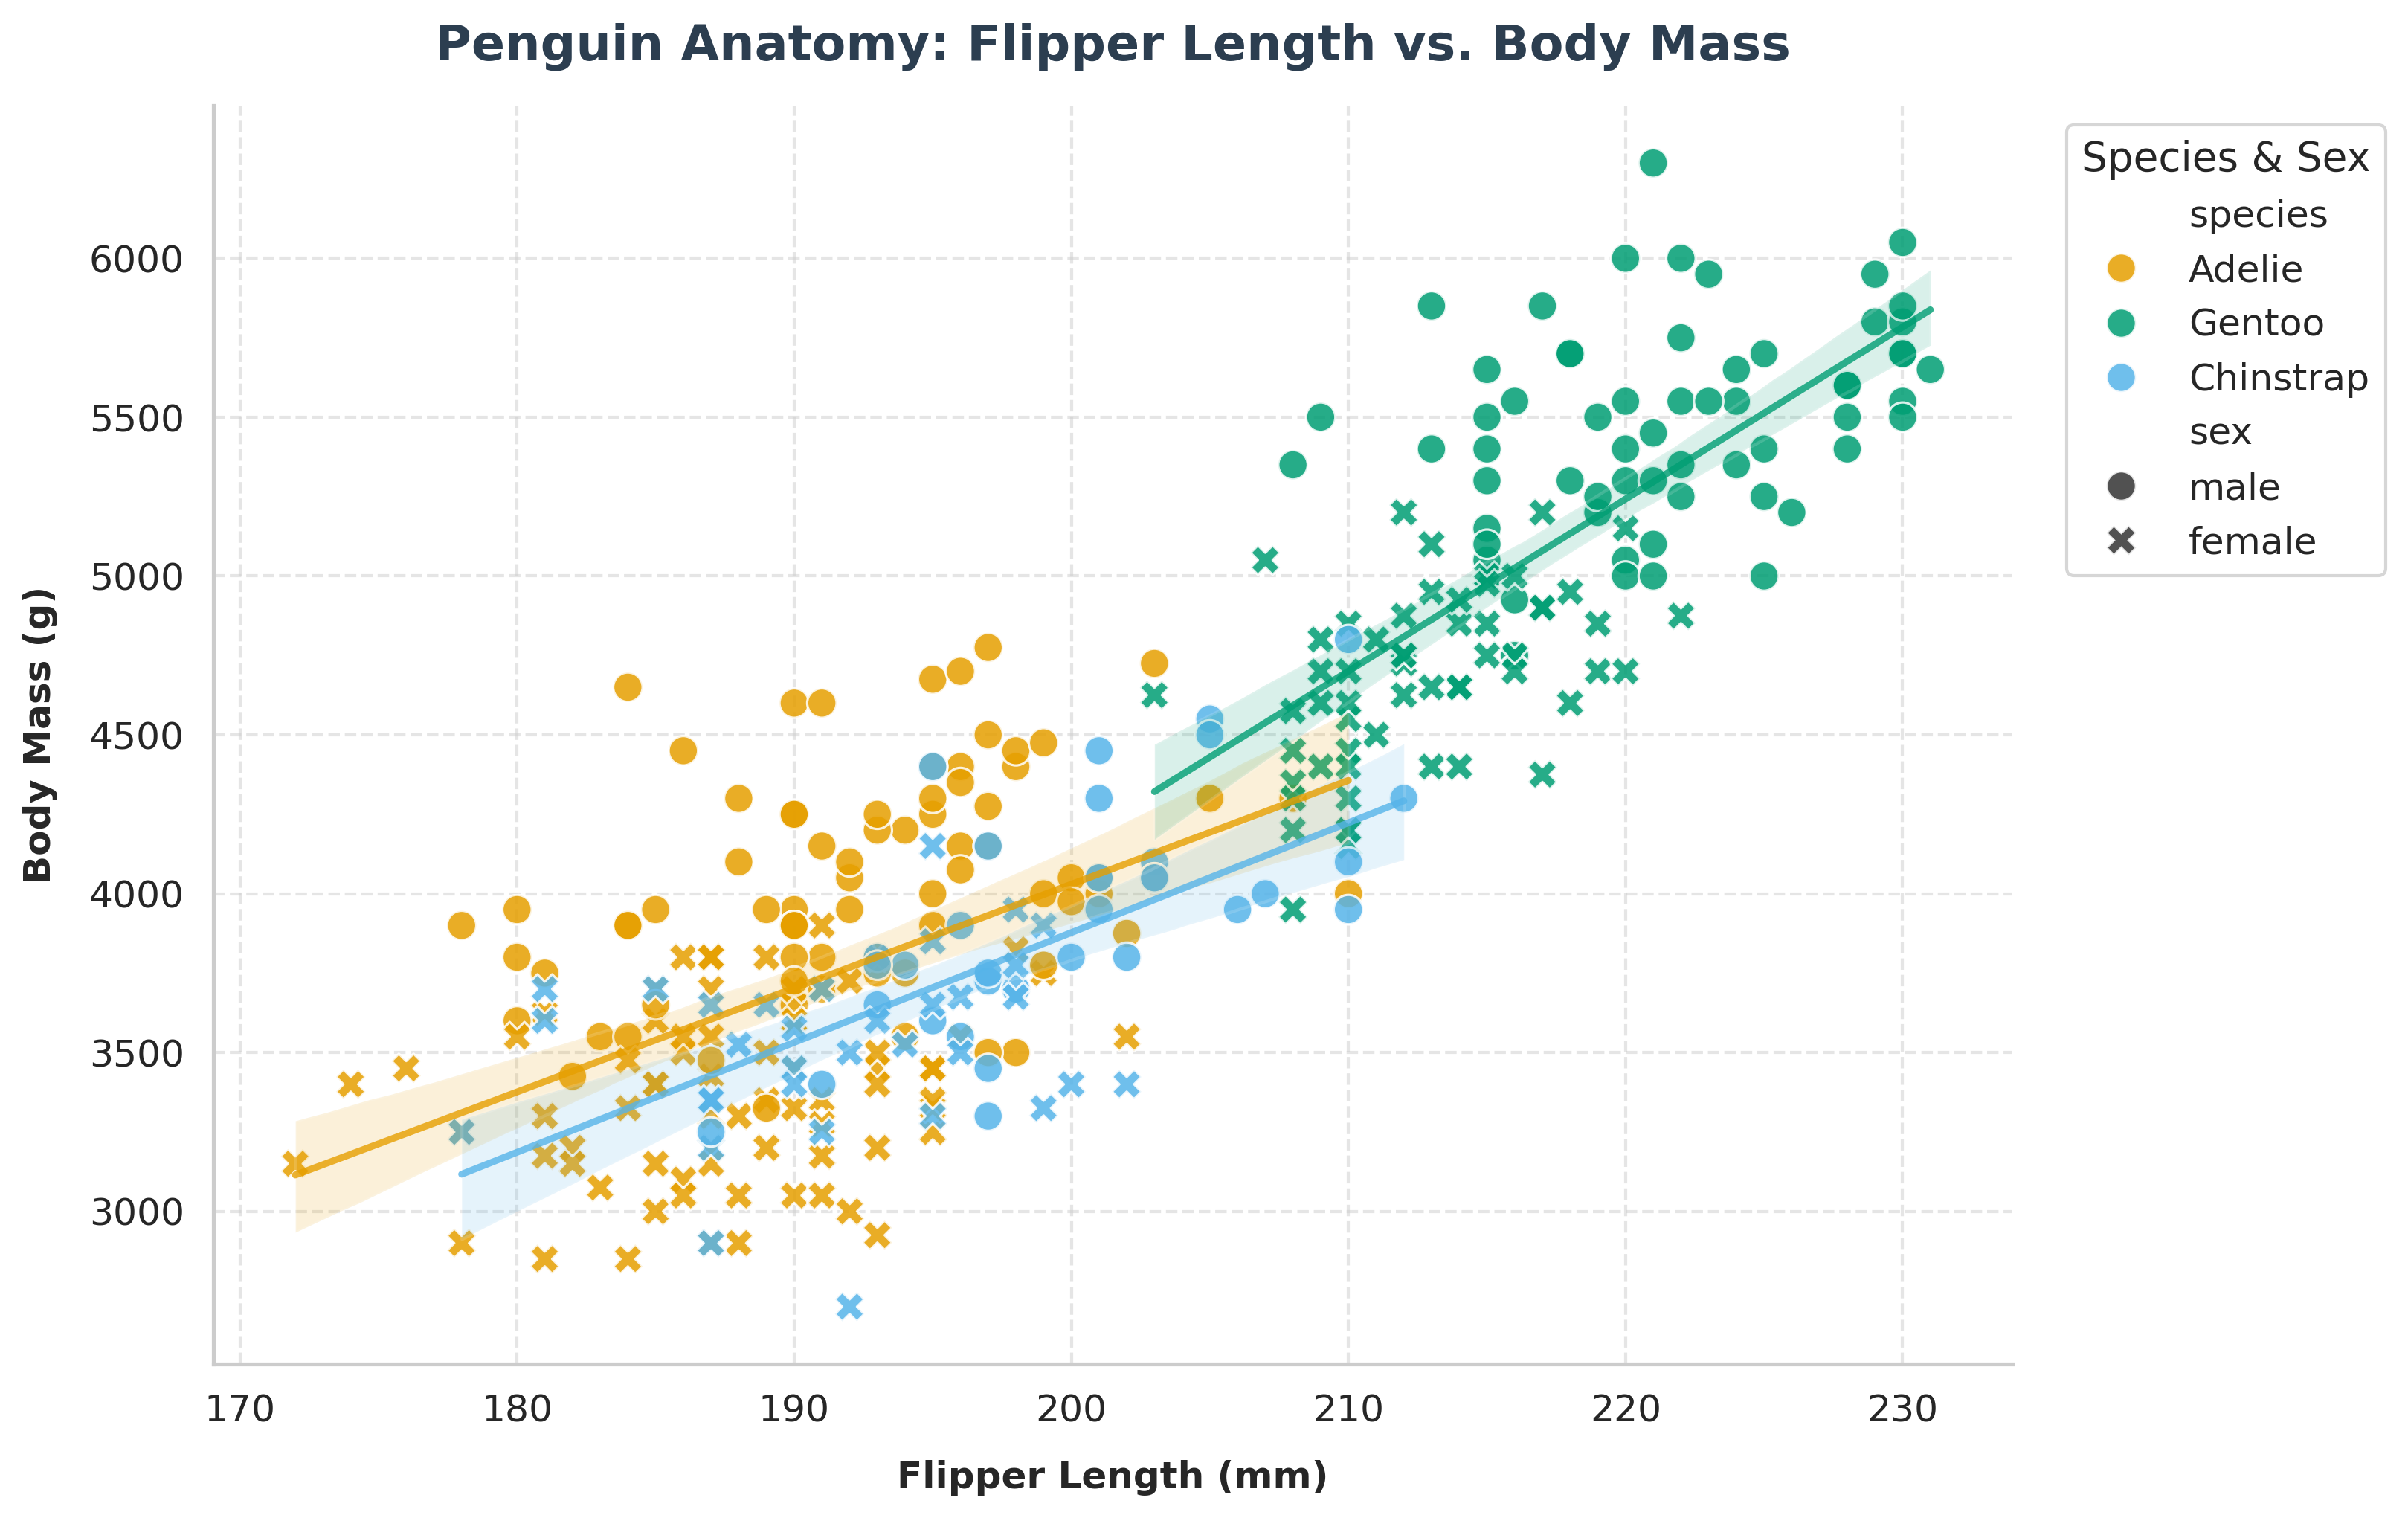

In [1]:
# Install required libraries if you don't have them:
# pip install pandas seaborn matplotlib

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load data directly from the TidyTuesday GitHub repository
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-04-15/penguins.csv"
penguins = pd.read_csv(url)

# Clean the data by dropping missing values in key columns
df = penguins.dropna(subset=["sex", "body_mass", "flipper_len"])

# Set up the matplotlib figure aesthetic
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(11, 7), dpi=300)

# Define a vibrant, colorblind-friendly palette
palette = {"Adelie": "#E69F00", "Chinstrap": "#56B4E9", "Gentoo": "#009E73"}

# 1. Create the scatter plot (hue for species, style for sex)
sns.scatterplot(
    data=df,
    x="flipper_len",
    y="body_mass",
    hue="species",
    style="sex",
    palette=palette,
    s=90,
    alpha=0.85,
    ax=ax,
)

# 2. Add individual linear regression trendlines for each species
for species, color in palette.items():
  subset = df[df["species"] == species]
  sns.regplot(
      data=subset,
      x="flipper_len",
      y="body_mass",
      scatter=False,
      ax=ax,
      color=color,
      line_kws={"linewidth": 2.2, "alpha": 0.8},
  )

# Informative titles and clean axis labels
ax.set_title(
    "Penguin Anatomy: Flipper Length vs. Body Mass",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="#2C3E50",
)
ax.set_xlabel("Flipper Length (mm)", fontsize=12, fontweight="bold", labelpad=10)
ax.set_ylabel("Body Mass (g)", fontsize=12, fontweight="bold", labelpad=10)

# Clean up legend positioning
ax.legend(
    title="Species & Sex", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True
)

# Grid and spine tweaks for modern aesthetic
ax.grid(True, linestyle="--", alpha=0.5)
sns.despine(top=True, right=True)
plt.tight_layout()

# Display the plot
plt.show()

# Optional: Save the plot as a high-res image
# fig.savefig("penguins_masterpiece_python.png", dpi=300, bbox_inches='tight')